# Preprocessing NLP - Avant / Apres

Ce notebook documente le nettoyage NLP appliqué pour la pipeline TF-IDF / ML classique (`src/data/preprocess.py`), et compare le texte **avant** (colonne `text`, sortie de l'Étape 2) et **après** (colonne `text_classical` : démojisation, minuscule, lemmatisation multilingue, suppression des mots vides).

**Important** : cette version nettoyée (`text_classical`) est réservée au pipeline TF-IDF + ML classique. Le pipeline Transformer (CamemBERT/RoBERTa, Étape 4) utilisera directement la colonne `text` d'origine, sans suppression des mots vides ni lemmatisation : ces modèles s'appuient sur le contexte syntaxique complet et perdent en performance si on le retire.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

df = pd.read_csv("../data/processed/revolut_reviews_nlp.csv", low_memory=False)
df.shape


(99493, 9)

## 1. Exemples avant / apres

In [2]:
sample = df.sample(10, random_state=3)[["language", "rating", "text", "text_classical"]]
sample


,language,rating,text,text_classical
22335,de,5,klasse,Klasse
79472,fr,1,nul on px pas faire de dépôt d'argent,nul px faire dépôt d'argent
18081,sv,5,Mycket bra.,bra
52842,de,5,Perfekt alles,perfekt
49677,fr,5,simple et facile à utiliser,simple facile utiliser
39392,ro,5,foarte bun,bun
85247,unknown,5,Always the best,always the best
9272,cs,2,Poslední dobou nějak nefungují převody a platby přes telefon,poslední doba fungovat převod platba telefon
95624,unknown,5,Super,super
53875,pl,5,Jest super!,Supera


On voit le double effet recherché : la casse, la ponctuation et les mots vides disparaissent, et les mots fléchis sont ramenés à leur forme de base (ex: "mangeons" -> "manger"). Les mots de sentiment ("bon", "good", "bien"...) ont été explicitement protégés contre la suppression -- ce n'était pas le comportement par défaut (voir section 4).

## 2. Longueur du texte : avant vs apres

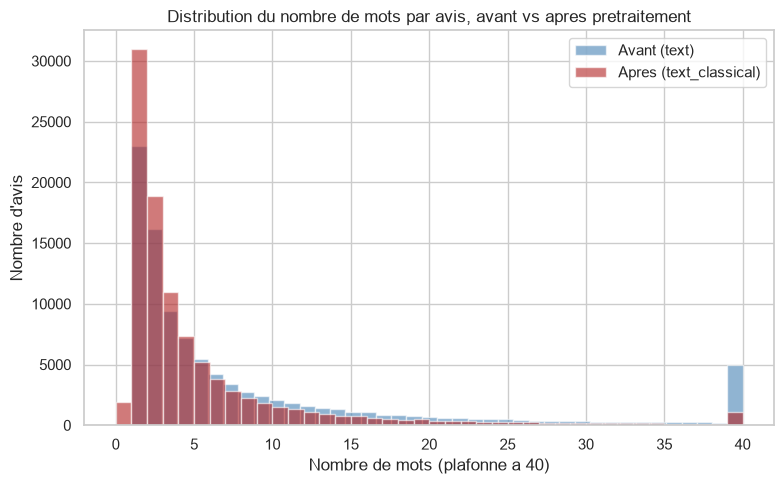

,words_before,words_after
count,99493.000000,99493.000000
mean,9.317299,5.177862
std,15.369777,8.108583
min,1.000000,0.000000
25%,2.000000,1.000000
50%,4.000000,2.000000
75%,10.000000,5.000000
max,657.000000,274.000000


In [3]:
df["words_before"] = df["text"].str.split().str.len()
df["words_after"] = df["text_classical"].fillna("").str.split().str.len()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["words_before"].clip(upper=40), bins=40, alpha=0.6, label="Avant (text)", color="steelblue")
ax.hist(df["words_after"].clip(upper=40), bins=40, alpha=0.6, label="Apres (text_classical)", color="firebrick")
ax.set_xlabel("Nombre de mots (plafonne a 40)")
ax.set_ylabel("Nombre d'avis")
ax.set_title("Distribution du nombre de mots par avis, avant vs apres pretraitement")
ax.legend()
plt.tight_layout()
plt.show()

df[["words_before", "words_after"]].describe()


La suppression des mots vides réduit la longueur moyenne d'environ un tiers : les avis courts ("c'est vraiment très bien" -> "vraiment bien") perdent leurs mots de liaison, ce qui est l'effet recherché pour un vectoriseur TF-IDF (qui ne profite pas des mots vides, très fréquents et peu discriminants).

## 3. Taille du vocabulaire : avant vs apres

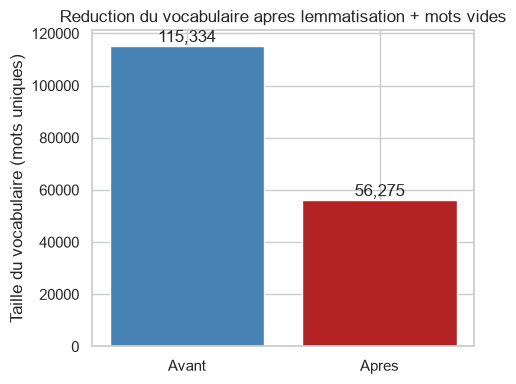

Reduction: 51.2%


In [4]:
def vocab_size(texts: pd.Series) -> int:
    vocab = set()
    for text in texts.dropna():
        vocab.update(text.lower().split())
    return len(vocab)

vocab_before = vocab_size(df["text"])
vocab_after = vocab_size(df["text_classical"])

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Avant", "Apres"], [vocab_before, vocab_after], color=["steelblue", "firebrick"])
ax.set_ylabel("Taille du vocabulaire (mots uniques)")
ax.set_title("Reduction du vocabulaire apres lemmatisation + mots vides")
for i, v in enumerate([vocab_before, vocab_after]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(f"Reduction: {(1 - vocab_after / vocab_before) * 100:.1f}%")


La lemmatisation regroupe les variantes flexionnelles d'un même mot ("mange", "manges", "mangeons" -> "manger"), ce qui réduit mécaniquement la taille du vocabulaire. C'est précisément l'effet recherché avant un TF-IDF : moins de colonnes creuses, plus de signal par mot retenu.

## 4. Mots frequents par polarite : avant vs apres

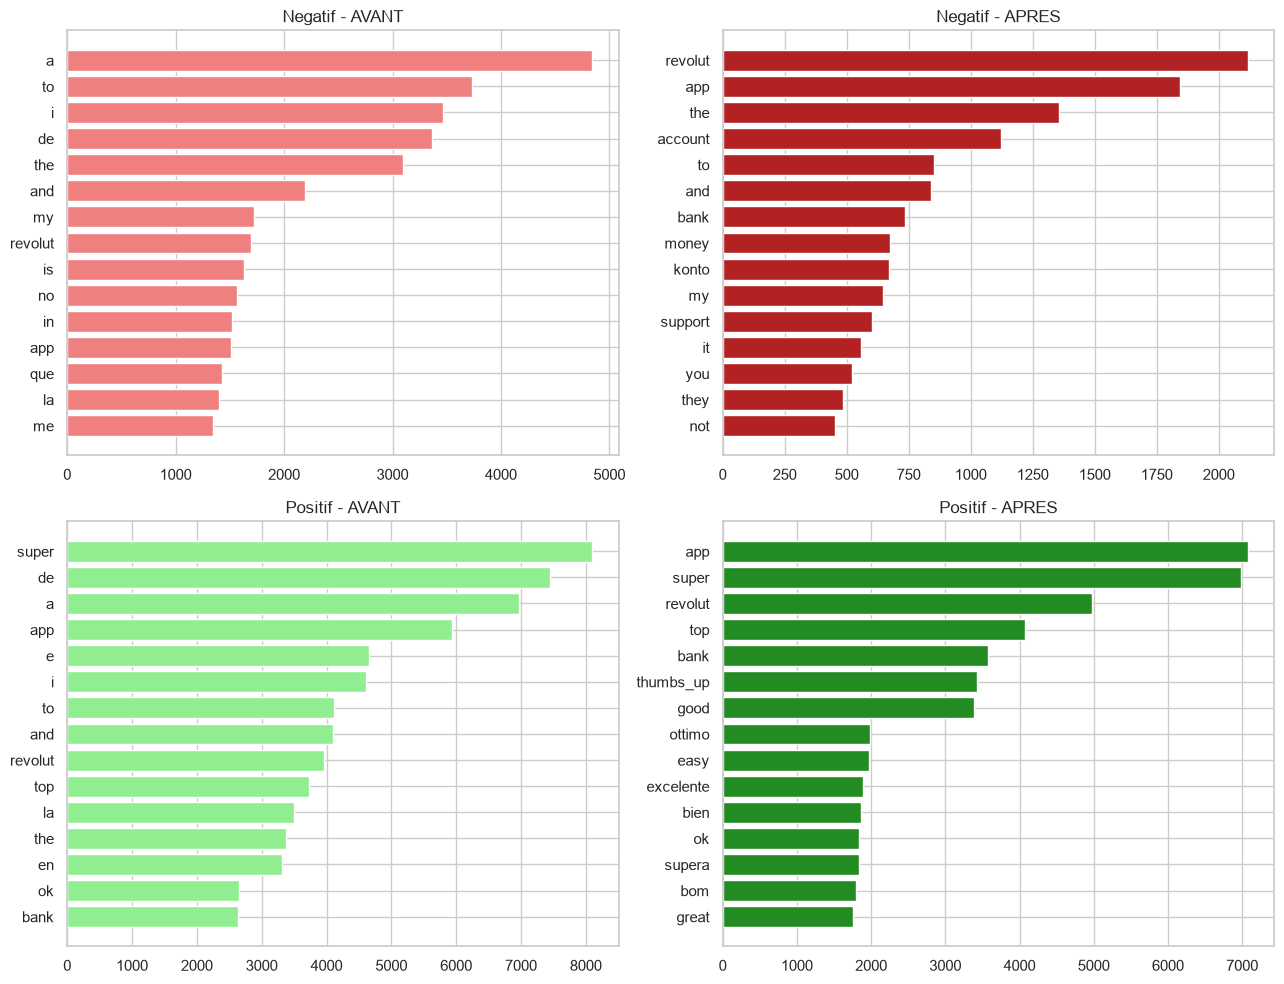

In [5]:
def top_words(texts: pd.Series, n: int = 15) -> list[tuple[str, int]]:
    counter: Counter[str] = Counter()
    for text in texts.dropna():
        counter.update(text.lower().split())
    return counter.most_common(n)

neg_before = top_words(df.loc[df["rating"] <= 2, "text"])
neg_after = top_words(df.loc[df["rating"] <= 2, "text_classical"])
pos_before = top_words(df.loc[df["rating"] >= 4, "text"])
pos_after = top_words(df.loc[df["rating"] >= 4, "text_classical"])

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, data, title, color in [
    (axes[0, 0], neg_before, "Negatif - AVANT", "lightcoral"),
    (axes[0, 1], neg_after, "Negatif - APRES", "firebrick"),
    (axes[1, 0], pos_before, "Positif - AVANT", "lightgreen"),
    (axes[1, 1], pos_after, "Positif - APRES", "forestgreen"),
]:
    ax.barh([w for w, _ in data[::-1]], [c for _, c in data[::-1]], color=color)
    ax.set_title(title)

plt.tight_layout()
plt.show()


**Avant** prétraitement, les mots les plus fréquents sont dominés par des mots vides multilingues (the, de, a, и, et...) qui n'apportent aucune information de polarité. **Après** prétraitement, ce bruit disparaît et les mots qui émergent sont directement liés au produit et au sentiment (good/great/bon côté positif ; bad/worst/horrible côté négatif), validant que le nettoyage améliore le signal exploitable par un modèle TF-IDF.

## 5. Point d'attention identifié pendant le developpement

Le premier essai utilisait directement les listes de mots vides du package `stopwordsiso`, sans vérification. Or ces listes génériques classaient à tort des mots de sentiment essentiels comme stopwords : **"good"**, **"great"**, **"best"** en anglais, **"bien"**, **"bon"** en français, **"bueno"** en espagnol, **"bom"** en portugais, **"gut"** en allemand, **"jó"** en hongrois, **"bra"** en suédois. Les supprimer aurait détruit une partie du signal de sentiment avant même d'entraîner un modèle.

Une liste de protection (`SENTIMENT_PROTECTED_WORDS` dans `src/data/preprocess.py`) a été ajoutée pour ces 15 langues, réduisant de 6045 à 1889 le nombre d'avis devenus vides après nettoyage (~69% de réduction). Les avis encore vides après nettoyage sont des cas légitimes (interjections pures comme "ok", texte composé uniquement de mots vides) et sont conservés tels quels ; ils seront traités au moment de la modélisation (Étape 4).